# Garbage Classification using EfficientNetB3

This notebook trains an EfficientNetB3 model for garbage classification using transfer learning.

**Model:** EfficientNetB3 (Pre-trained on ImageNet)  
**Input Size:** 300x300x3  
**Strategy:** Two-phase training with compound scaling optimization

## Step 1: Install Required Libraries

In [ ]:
!pip install roboflow tensorflow opencv-python matplotlib scikit-learn pillow seaborn

## Step 2: Download Dataset from Roboflow

In [ ]:
from roboflow import Roboflow
import os

# Initialize Roboflow with your API key
rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")
project = rf.workspace("material-identification").project("garbage-classification-3")
version = project.version(1)

# Download dataset in a format suitable for classification (e.g., "tensorflow")
# Check if the dataset is already downloaded and if not, download it.
dataset_dir = "GARBAGE-CLASSIFICATION-3-1"  # Assuming this is the new dataset folder name
if not os.path.exists(dataset_dir):
    dataset = version.download("tensorflow")
    print(f"Dataset downloaded to: {dataset.location}")
else:
    print(f"Dataset already exists at: {dataset_dir}")
    dataset = type('obj', (object,), {'location': dataset_dir})() # Create a mock object with location attribute

loading Roboflow workspace...
loading Roboflow project...
Dataset already exists at: GARBAGE-CLASSIFICATION-3-1


In [ ]:
import shutil
from pathlib import Path

def reorganize_dataset(base_dir):
    """
    Reorganize flat dataset structure into class subdirectories.
    Files are named like 'classname123_jpg.rf.hash.jpg'
    """
    for split in ['train', 'valid', 'test']:
        split_dir = os.path.join(base_dir, split)

        if not os.path.exists(split_dir):
            print(f"Directory not found: {split_dir}")
            continue

        # Get all image files (skip csv files)
        all_items = os.listdir(split_dir)
        files = [f for f in all_items if os.path.isfile(os.path.join(split_dir, f)) and f.endswith(('.jpg', '.jpeg', '.png'))]

        if not files:
            print(f"{split} - No images in root directory (already organized)")
            continue

        print(f"\nReorganizing {split} directory...")
        print(f"Found {len(files)} images to organize...")

        # Extract class names from filenames and create directories
        class_names = set()
        for filename in files:
            # Extract class name (everything before the first digit)
            class_name = ''.join([c for c in filename.split('_')[0] if not c.isdigit()])
            if class_name:
                class_names.add(class_name)

        print(f"Found classes: {sorted(class_names)}")

        # Create class directories
        for class_name in class_names:
            class_dir = os.path.join(split_dir, class_name)
            os.makedirs(class_dir, exist_ok=True)

        # Move files to appropriate class directories
        moved_count = 0
        for filename in files:
            # Extract class name
            class_name = ''.join([c for c in filename.split('_')[0] if not c.isdigit()])

            if class_name in class_names:
                src = os.path.join(split_dir, filename)
                dst = os.path.join(split_dir, class_name, filename)

                # Only move if source exists and destination doesn't
                if os.path.exists(src) and not os.path.exists(dst):
                    shutil.move(src, dst)
                    moved_count += 1

        print(f"Moved {moved_count} files into class subdirectories")

# Reorganize the dataset
dataset_path = dataset.location
print(f"Reorganizing dataset at: {dataset_path}")
reorganize_dataset(dataset_path)
print("\nDataset reorganization complete!")

Reorganizing dataset at: GARBAGE-CLASSIFICATION-3-1
train - No images in root directory (already organized)
valid - No images in root directory (already organized)
test - No images in root directory (already organized)

Dataset reorganization complete!


In [ ]:
import random
from collections import defaultdict
import os
import shutil

def balance_dataset_splits(base_dir, train_ratio=0.7, valid_ratio=0.2, test_ratio=0.1, tolerance=0.05):
    """
    Collect all images from all splits and redistribute them with proper ratios.
    Ensures all classes appear in train, valid, and test splits.
    Only reorganizes if dataset is found to be unbalanced.
    """
    print("=" * 60)
    print("Checking dataset balance...")
    print("=" * 60)

    # Collect all images from all splits
    all_images = defaultdict(list)  # class_name -> list of image paths
    split_counts = defaultdict(lambda: defaultdict(int))  # split -> class -> count

    for split in ['train', 'valid', 'test']:
        split_dir = os.path.join(base_dir, split)
        if not os.path.exists(split_dir):
            continue

        # Look for class subdirectories
        for class_name in os.listdir(split_dir):
            class_path = os.path.join(split_dir, class_name)
            if not os.path.isdir(class_path):
                continue

            # Get all images in this class directory
            images = [f for f in os.listdir(class_path)
                     if f.endswith(('.jpg', '.jpeg', '.png'))]

            for img in images:
                img_path = os.path.join(class_path, img)
                all_images[class_name].append(img_path)
                split_counts[split][class_name] += 1

    if not all_images:
        print("No images found in class subdirectories!")
        return

    print(f"\nFound {len(all_images)} classes:")
    for class_name, imgs in all_images.items():
        print(f"  - {class_name}: {len(imgs)} images")

    # Check if dataset is balanced
    print("\nCurrent distribution:")
    print(f"{'Class':<15} {'Train':<10} {'Valid':<10} {'Test':<10} {'Total':<10}")
    print("-" * 60)

    needs_balancing = False
    missing_classes = []

    for class_name in sorted(all_images.keys()):
        train_count = split_counts['train'].get(class_name, 0)
        valid_count = split_counts['valid'].get(class_name, 0)
        test_count = split_counts['test'].get(class_name, 0)
        total_count = len(all_images[class_name])

        print(f"{class_name:<15} {train_count:<10} {valid_count:<10} {test_count:<10} {total_count:<10}")

        # Check if any split is missing this class
        if train_count == 0 or valid_count == 0 or test_count == 0:
            needs_balancing = True
            missing_classes.append(class_name)

        # Check if ratios are off
        actual_train_ratio = train_count / total_count
        actual_valid_ratio = valid_count / total_count
        actual_test_ratio = test_count / total_count

        if (abs(actual_train_ratio - train_ratio) > tolerance or
            abs(actual_valid_ratio - valid_ratio) > tolerance or
            abs(actual_test_ratio - test_ratio) > tolerance):
            needs_balancing = True

    if not needs_balancing:
        print("\n✓ Dataset is already balanced! No reorganization needed.")
        return

    print("\n⚠ Dataset is UNBALANCED:")
    if missing_classes:
        print(f"  - Missing classes in some splits: {', '.join(missing_classes)}")
    print(f"  - Target ratios: Train={train_ratio:.0%}, Valid={valid_ratio:.0%}, Test={test_ratio:.0%}")
    print("\nProceeding with rebalancing...")

    # Shuffle and split for each class
    random.seed(42)  # For reproducibility

    train_files = defaultdict(list)
    valid_files = defaultdict(list)
    test_files = defaultdict(list)

    for class_name, image_paths in all_images.items():
        # Shuffle images
        shuffled = image_paths.copy()
        random.shuffle(shuffled)

        # Calculate split points
        total = len(shuffled)
        train_end = int(total * train_ratio)
        valid_end = train_end + int(total * valid_ratio)

        # Split
        train_files[class_name] = shuffled[:train_end]
        valid_files[class_name] = shuffled[train_end:valid_end]
        test_files[class_name] = shuffled[valid_end:]

    print("\nNew split distribution:")
    print(f"{'Class':<15} {'Train':<10} {'Valid':<10} {'Test':<10} {'Total':<10}")
    print("-" * 60)

    for class_name in sorted(all_images.keys()):
        train_count = len(train_files[class_name])
        valid_count = len(valid_files[class_name])
        test_count = len(test_files[class_name])
        total_count = train_count + valid_count + test_count
        print(f"{class_name:<15} {train_count:<10} {valid_count:<10} {test_count:<10} {total_count:<10}")

    # Now move files to their new locations
    print("\n" + "=" * 60)
    print("Reorganizing files...")
    print("=" * 60)

    # First, create new directories
    for split in ['train', 'valid', 'test']:
        for class_name in all_images.keys():
            new_dir = os.path.join(base_dir, split, class_name)
            os.makedirs(new_dir, exist_ok=True)

    # Move files
    move_count = 0
    for split_name, file_dict in [('train', train_files), ('valid', valid_files), ('test', test_files)]:
        for class_name, file_paths in file_dict.items():
            dest_dir = os.path.join(base_dir, split_name, class_name)
            for src_path in file_paths:
                filename = os.path.basename(src_path)
                dest_path = os.path.join(dest_dir, filename)

                # Only move if not already in the right place
                if src_path != dest_path:
                    # If destination exists, remove it first
                    if os.path.exists(dest_path):
                        os.remove(dest_path)
                    shutil.move(src_path, dest_path)
                    move_count += 1

    print(f"✓ Reorganized {move_count} files")

    # Clean up empty directories
    for split in ['train', 'valid', 'test']:
        split_dir = os.path.join(base_dir, split)
        if os.path.exists(split_dir):
            for class_name in os.listdir(split_dir):
                class_path = os.path.join(split_dir, class_name)
                if os.path.isdir(class_path):
                    try:
                        if not os.listdir(class_path):
                            os.rmdir(class_path)
                    except:
                        pass

    print("✓ Dataset balancing complete!\n")

# Balance the dataset
balance_dataset_splits(dataset_path)


Checking dataset balance...

Found 6 classes:
  - paper: 2891 images
  - biodegradable: 3692 images
  - plastic: 1928 images
  - metal: 2074 images
  - cardboard: 2379 images
  - glass: 4401 images

Current distribution:
Class           Train      Valid      Test       Total     
------------------------------------------------------------
biodegradable   2584       738        370        3692      
cardboard       1665       475        239        2379      
glass           3080       880        441        4401      
metal           1451       414        209        2074      
paper           2023       578        290        2891      
plastic         1349       385        194        1928      

✓ Dataset is already balanced! No reorganization needed.


## Step 3: Import Required Libraries

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 4: Prepare Data Generators

EfficientNetB3 uses 300x300 input size for optimal performance.

In [ ]:
# Set dataset paths
dataset_path = dataset.location
train_dir = os.path.join(dataset_path, 'train')
val_dir = os.path.join(dataset_path, 'valid')
test_dir = os.path.join(dataset_path, 'test')

print(f"Dataset path: {dataset_path}")
print(f"Train directory: {train_dir}")
print(f"Validation directory: {val_dir}")
print(f"Test directory: {test_dir}")

# Image parameters for EfficientNetB3
IMG_SIZE = 300  # EfficientNetB3 optimal input size
BATCH_SIZE = 32  # Increased for more stable gradients

# Moderate data augmentation (matching ResNet50 strategy)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Only rescaling for validation and test
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Create generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# Get class information
num_classes = len(train_generator.class_indices)
class_names = list(train_generator.class_indices.keys())

print(f"\nNumber of classes: {num_classes}")
print(f"Class names: {class_names}")
print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {val_generator.samples}")
print(f"Test samples: {test_generator.samples}")


Dataset path: GARBAGE-CLASSIFICATION-3-1
Train directory: GARBAGE-CLASSIFICATION-3-1/train
Validation directory: GARBAGE-CLASSIFICATION-3-1/valid
Test directory: GARBAGE-CLASSIFICATION-3-1/test
Found 12152 images belonging to 6 classes.
Found 3470 images belonging to 6 classes.
Found 1743 images belonging to 6 classes.

Number of classes: 6
Class names: ['biodegradable', 'cardboard', 'glass', 'metal', 'paper', 'plastic']
Training samples: 12152
Validation samples: 3470
Test samples: 1743


## Step 5: Visualize Sample Images with Augmentation

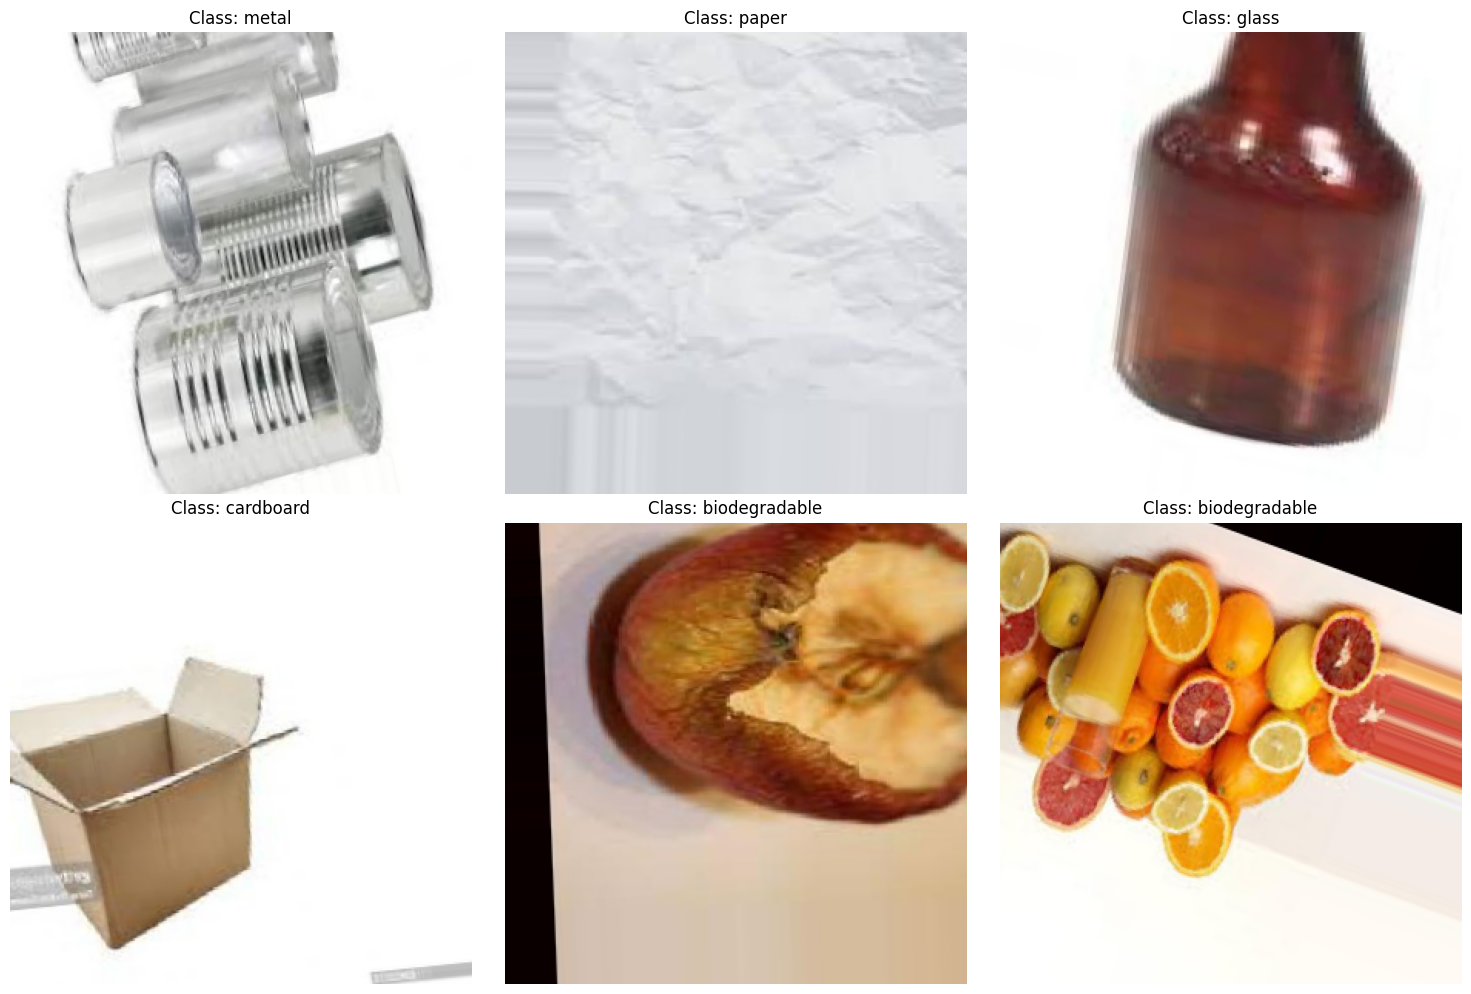

In [ ]:
# Display sample images with their labels
sample_batch, sample_labels = next(train_generator)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for idx in range(6):
    axes[idx].imshow(sample_batch[idx])
    class_idx = np.argmax(sample_labels[idx])
    axes[idx].set_title(f'Class: {class_names[class_idx]}', fontsize=12)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()


## Step 6: Build EfficientNetB3 Model

EfficientNet uses compound scaling for optimal efficiency and accuracy balance.

In [ ]:
# Load pre-trained EfficientNetB3 without top layers
base_model = EfficientNetB3(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze base model layers initially
base_model.trainable = False

# Build streamlined model with simpler head (matching ResNet50 approach)
model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Compile model with appropriate learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_accuracy')]
)

print("\nModel Architecture:")
model.summary()



Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb3 (Functional)     │ (None, 10, 10, 1536)   │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       786,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,709,493 (44.67 MB)

 Trainable params: 922,886 (3.52 MB)

 Non-trainable params: 10,786,607 (41.15 MB)

## Step 7: Setup Callbacks and Train (Phase 1)

In [ ]:
# Define callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        'efficientnet_garbage_phase1.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# Train model - Phase 1 (frozen base)
print("\nPhase 1: Training with frozen EfficientNetB3 base...")
history_phase1 = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

print("Phase 1 training completed!")



Phase 1: Training with frozen EfficientNetB3 base...


Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.


Epoch 1/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 781ms/step - accuracy: 0.1908 - loss: 2.2357 - top3_accuracy: 0.5313
Epoch 1: val_accuracy improved from -inf to 0.22478, saving model to efficientnet_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 397s 891ms/step - accuracy: 0.1908 - loss: 2.2354 - top3_accuracy: 0.5314 - val_accuracy: 0.2248 - val_loss: 1.7435 - val_top3_accuracy: 0.5657 - learning_rate: 1.0000e-05
Epoch 2/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 688ms/step - accuracy: 0.2447 - loss: 1.9750 - top3_accuracy: 0.5880
Epoch 2: val_accuracy improved from 0.22478 to 0.34640, saving model to efficientnet_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 275s 724ms/step - accuracy: 0.2447 - loss: 1.9750 - top3_accuracy: 0.5880 - val_accuracy: 0.3464 - val_loss: 1.6548 - val_top3_accuracy: 0.6807 - learning_rate: 1.0000e-05
Epoch 3/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 690ms/step - accuracy: 0.2454 - loss: 1.9173 - top3_accuracy: 0.5989
Epoch 3: val_accuracy improved from 0.34640 to 0.35303, saving model to efficientnet_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 276s 727ms/step - accuracy: 0.2454 - loss: 1.9173 - top3_accuracy: 0.5989 - val_accuracy: 0.3530 - val_loss: 1.6428 - val_top3_accuracy: 0.6908 - learning_rate: 1.0000e-05
Epoch 4/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 683ms/step - accuracy: 0.2558 - loss: 1.8644 - top3_accuracy: 0.6132
Epoch 4: val_accuracy did not improve from 0.35303
380/380 ━━━━━━━━━━━━━━━━━━━━ 273s 717ms/step - accuracy: 0.2558 - loss: 1.8644 - top3_accuracy: 0.6132 - val_accuracy: 0.3501 - val_loss: 1.6416 - val_top3_accuracy: 0.7017 - learning_rate: 1.0000e-05
Epoch 5/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 678ms/step - accuracy: 0.2599 - loss: 1.8514 - top3_accuracy: 0.6214
Epoch 5: val_accuracy did not improve from 0.35303
380/380 ━━━━━━━━━━━━━━━━━━━━ 271s 713ms/step - accuracy: 0.2599 - loss: 1.8514 - top3_accuracy: 0.6214 - val_accuracy: 0.3470 - val_loss: 1.6445 - val_top3_accuracy: 0.6813 - learning_rate: 1.0000e-05
Epoch 6/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 684ms/step - accuracy: 0.264

380/380 ━━━━━━━━━━━━━━━━━━━━ 274s 720ms/step - accuracy: 0.2646 - loss: 1.8187 - top3_accuracy: 0.6140 - val_accuracy: 0.3553 - val_loss: 1.6347 - val_top3_accuracy: 0.6735 - learning_rate: 1.0000e-05
Epoch 7/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 684ms/step - accuracy: 0.2798 - loss: 1.7815 - top3_accuracy: 0.6342
Epoch 7: val_accuracy did not improve from 0.35533
380/380 ━━━━━━━━━━━━━━━━━━━━ 273s 717ms/step - accuracy: 0.2798 - loss: 1.7815 - top3_accuracy: 0.6342 - val_accuracy: 0.3536 - val_loss: 1.6351 - val_top3_accuracy: 0.6957 - learning_rate: 1.0000e-05
Epoch 8/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 685ms/step - accuracy: 0.2776 - loss: 1.7827 - top3_accuracy: 0.6274
Epoch 8: val_accuracy did not improve from 0.35533
380/380 ━━━━━━━━━━━━━━━━━━━━ 274s 720ms/step - accuracy: 0.2776 - loss: 1.7827 - top3_accuracy: 0.6274 - val_accuracy: 0.3542 - val_loss: 1.6276 - val_top3_accuracy: 0.7061 - learning_rate: 1.0000e-05
Epoch 9/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 682ms/step - accuracy: 0.292

380/380 ━━━━━━━━━━━━━━━━━━━━ 273s 718ms/step - accuracy: 0.2923 - loss: 1.7702 - top3_accuracy: 0.6253 - val_accuracy: 0.3562 - val_loss: 1.6302 - val_top3_accuracy: 0.7061 - learning_rate: 1.0000e-05
Epoch 10/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 681ms/step - accuracy: 0.2785 - loss: 1.7720 - top3_accuracy: 0.6301
Epoch 10: val_accuracy improved from 0.35620 to 0.36081, saving model to efficientnet_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 273s 718ms/step - accuracy: 0.2785 - loss: 1.7720 - top3_accuracy: 0.6301 - val_accuracy: 0.3608 - val_loss: 1.6286 - val_top3_accuracy: 0.7081 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 8.
Phase 1 training completed!


## Step 8: Fine-tune the Model (Phase 2)

Unfreeze and fine-tune the top layers of EfficientNetB3.

In [ ]:
# Unfreeze the base model
base_model.trainable = True

# Freeze bottom layers, unfreeze top layers (last 20 layers)
fine_tune_at = len(base_model.layers) - 20

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"Number of trainable layers: {len([l for l in base_model.layers if l.trainable])}")

# Recompile with lower learning rate for fine-tuning
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_accuracy')]
)

# Update checkpoint callback
callbacks[2] = keras.callbacks.ModelCheckpoint(
    'efficientnet_garbage_best.h5',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Train model - Phase 2 (fine-tuning)
print("\nPhase 2: Fine-tuning with unfrozen layers...")
history_phase2 = model.fit(
    train_generator,
    epochs=15,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

print("Phase 2 training completed!")


Number of trainable layers: 20

Phase 2: Fine-tuning with unfrozen layers...
Epoch 1/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 735ms/step - accuracy: 0.2835 - loss: 1.7826 - top3_accuracy: 0.6238
Epoch 1: val_accuracy improved from -inf to 0.35303, saving model to efficientnet_garbage_best.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 352s 819ms/step - accuracy: 0.2835 - loss: 1.7826 - top3_accuracy: 0.6238 - val_accuracy: 0.3530 - val_loss: 1.6330 - val_top3_accuracy: 0.6914 - learning_rate: 1.0000e-05
Epoch 2/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 688ms/step - accuracy: 0.2803 - loss: 1.7736 - top3_accuracy: 0.6275
Epoch 2: val_accuracy did not improve from 0.35303
380/380 ━━━━━━━━━━━━━━━━━━━━ 275s 722ms/step - accuracy: 0.2803 - loss: 1.7736 - top3_accuracy: 0.6275 - val_accuracy: 0.3516 - val_loss: 1.6314 - val_top3_accuracy: 0.7017 - learning_rate: 1.0000e-05
Epoch 3/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 690ms/step - accuracy: 0.2865 - loss: 1.7597 - top3_accuracy: 0.6318
Epoch 3: val_accuracy did not improve from 0.35303
380/380 ━━━━━━━━━━━━━━━━━━━━ 275s 724ms/step - accuracy: 0.2865 - loss: 1.7597 - top3_accuracy: 0.6318 - val_accuracy: 0.3510 - val_loss: 1.6294 - val_top3_accuracy: 0.6798 - learning_rate: 1.0000e-05
Epoch 4/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 681ms/step - accuracy: 0.297

380/380 ━━━━━━━━━━━━━━━━━━━━ 273s 717ms/step - accuracy: 0.2972 - loss: 1.7440 - top3_accuracy: 0.6415 - val_accuracy: 0.3565 - val_loss: 1.6289 - val_top3_accuracy: 0.6986 - learning_rate: 1.0000e-05
Epoch 5/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 685ms/step - accuracy: 0.2953 - loss: 1.7340 - top3_accuracy: 0.6351
Epoch 5: val_accuracy improved from 0.35648 to 0.36052, saving model to efficientnet_garbage_best.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 274s 721ms/step - accuracy: 0.2953 - loss: 1.7340 - top3_accuracy: 0.6351 - val_accuracy: 0.3605 - val_loss: 1.6268 - val_top3_accuracy: 0.7040 - learning_rate: 1.0000e-05
Epoch 6/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 680ms/step - accuracy: 0.3032 - loss: 1.7247 - top3_accuracy: 0.6407
Epoch 6: val_accuracy did not improve from 0.36052
380/380 ━━━━━━━━━━━━━━━━━━━━ 271s 714ms/step - accuracy: 0.3032 - loss: 1.7247 - top3_accuracy: 0.6407 - val_accuracy: 0.3582 - val_loss: 1.6289 - val_top3_accuracy: 0.6836 - learning_rate: 1.0000e-05
Epoch 7/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 687ms/step - accuracy: 0.2897 - loss: 1.7379 - top3_accuracy: 0.6495
Epoch 7: val_accuracy did not improve from 0.36052
380/380 ━━━━━━━━━━━━━━━━━━━━ 274s 722ms/step - accuracy: 0.2897 - loss: 1.7379 - top3_accuracy: 0.6495 - val_accuracy: 0.3594 - val_loss: 1.6245 - val_top3_accuracy: 0.6790 - learning_rate: 1.0000e-05
Epoch 8/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 677ms/step - accuracy: 0.299

380/380 ━━━━━━━━━━━━━━━━━━━━ 271s 712ms/step - accuracy: 0.3158 - loss: 1.6977 - top3_accuracy: 0.6528 - val_accuracy: 0.3611 - val_loss: 1.6173 - val_top3_accuracy: 0.7107 - learning_rate: 1.0000e-05
Epoch 14/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 681ms/step - accuracy: 0.3155 - loss: 1.7122 - top3_accuracy: 0.6547
Epoch 14: val_accuracy did not improve from 0.36110
380/380 ━━━━━━━━━━━━━━━━━━━━ 272s 715ms/step - accuracy: 0.3155 - loss: 1.7122 - top3_accuracy: 0.6547 - val_accuracy: 0.3556 - val_loss: 1.6110 - val_top3_accuracy: 0.7144 - learning_rate: 1.0000e-05
Epoch 15/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 684ms/step - accuracy: 0.3143 - loss: 1.7000 - top3_accuracy: 0.6578
Epoch 15: val_accuracy did not improve from 0.36110
380/380 ━━━━━━━━━━━━━━━━━━━━ 273s 718ms/step - accuracy: 0.3143 - loss: 1.6999 - top3_accuracy: 0.6578 - val_accuracy: 0.3585 - val_loss: 1.6108 - val_top3_accuracy: 0.7049 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 15.
Phase 2

## Step 9: Visualize Training Metrics

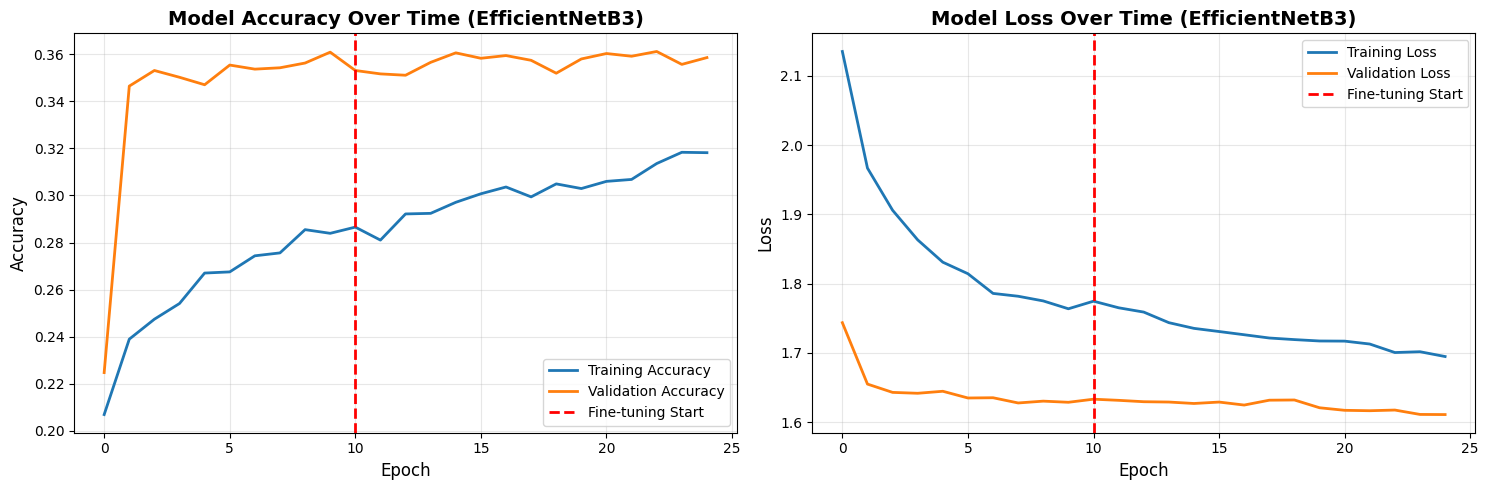

In [ ]:
# Combine histories
history_combined = {
    'accuracy': history_phase1.history['accuracy'] + history_phase2.history['accuracy'],
    'val_accuracy': history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy'],
    'loss': history_phase1.history['loss'] + history_phase2.history['loss'],
    'val_loss': history_phase1.history['val_loss'] + history_phase2.history['val_loss']
}

# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
phase1_end = len(history_phase1.history['accuracy'])

# Accuracy plot
ax1.plot(history_combined['accuracy'], label='Training Accuracy', linewidth=2)
ax1.plot(history_combined['val_accuracy'], label='Validation Accuracy', linewidth=2)
ax1.axvline(x=phase1_end, color='red', linestyle='--', label='Fine-tuning Start', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('Model Accuracy Over Time (EfficientNetB3)', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Loss plot
ax2.plot(history_combined['loss'], label='Training Loss', linewidth=2)
ax2.plot(history_combined['val_loss'], label='Validation Loss', linewidth=2)
ax2.axvline(x=phase1_end, color='red', linestyle='--', label='Fine-tuning Start', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('Model Loss Over Time (EfficientNetB3)', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Step 10: Comprehensive Model Evaluation

In [ ]:
# Evaluate on validation set
print("Evaluating EfficientNetB3 model on validation set...")
val_loss, val_accuracy, val_top3_accuracy = model.evaluate(val_generator)

print(f"\n{'='*50}")
print(f"VALIDATION METRICS - EfficientNetB3")
print(f"{'='*50}")
print(f"Loss: {val_loss:.4f}")
print(f"Accuracy: {val_accuracy:.4f} ({val_accuracy*100:.2f}%)")
print(f"Top-3 Accuracy: {val_top3_accuracy:.4f} ({val_top3_accuracy*100:.2f}%)")
print(f"{'='*50}")

# Evaluate on test set
print("\nEvaluating EfficientNetB3 model on test set...")
test_loss, test_accuracy, test_top3_accuracy = model.evaluate(test_generator)

print(f"\n{'='*50}")
print(f"TEST METRICS - EfficientNetB3")
print(f"{'='*50}")
print(f"Loss: {test_loss:.4f}")
print(f"Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Top-3 Accuracy: {test_top3_accuracy:.4f} ({test_top3_accuracy*100:.2f}%)")
print(f"{'='*50}")


Evaluating EfficientNetB3 model on validation set...
109/109 ━━━━━━━━━━━━━━━━━━━━ 13s 122ms/step - accuracy: 0.4721 - loss: 1.4939 - top3_accuracy: 0.7469

VALIDATION METRICS - EfficientNetB3
Loss: 1.6108
Accuracy: 0.3585 (35.85%)
Top-3 Accuracy: 0.7049 (70.49%)

Evaluating EfficientNetB3 model on test set...
55/55 ━━━━━━━━━━━━━━━━━━━━ 23s 414ms/step - accuracy: 0.4746 - loss: 1.4731 - top3_accuracy: 0.7486

TEST METRICS - EfficientNetB3
Loss: 1.5919
Accuracy: 0.3655 (36.55%)
Top-3 Accuracy: 0.7149 (71.49%)


## Step 11: Generate Detailed Confusion Matrix

55/55 ━━━━━━━━━━━━━━━━━━━━ 28s 310ms/step


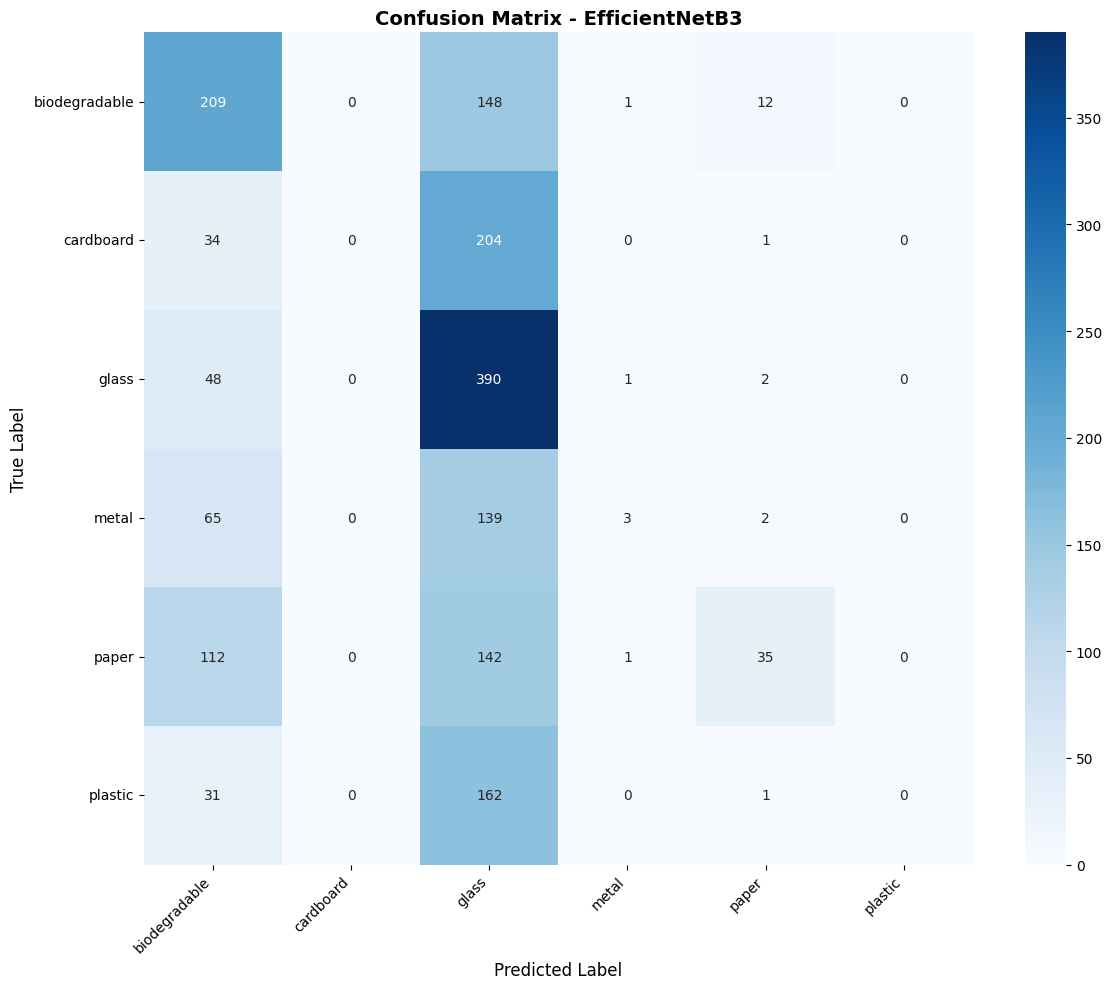


Detailed Classification Report:
               precision    recall  f1-score   support

biodegradable     0.4188    0.5649    0.4810       370
    cardboard     0.0000    0.0000    0.0000       239
        glass     0.3291    0.8844    0.4797       441
        metal     0.5000    0.0144    0.0279       209
        paper     0.6604    0.1207    0.2041       290
      plastic     0.0000    0.0000    0.0000       194

     accuracy                         0.3655      1743
    macro avg     0.3181    0.2640    0.1988      1743
 weighted avg     0.3420    0.3655    0.2608      1743



Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


In [ ]:
# Get predictions for confusion matrix
test_generator.reset()
predictions = model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes

# Compute confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - EfficientNetB3', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Detailed classification report
print("\nDetailed Classification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_names, digits=4))


## Step 12: Per-Class Performance Analysis


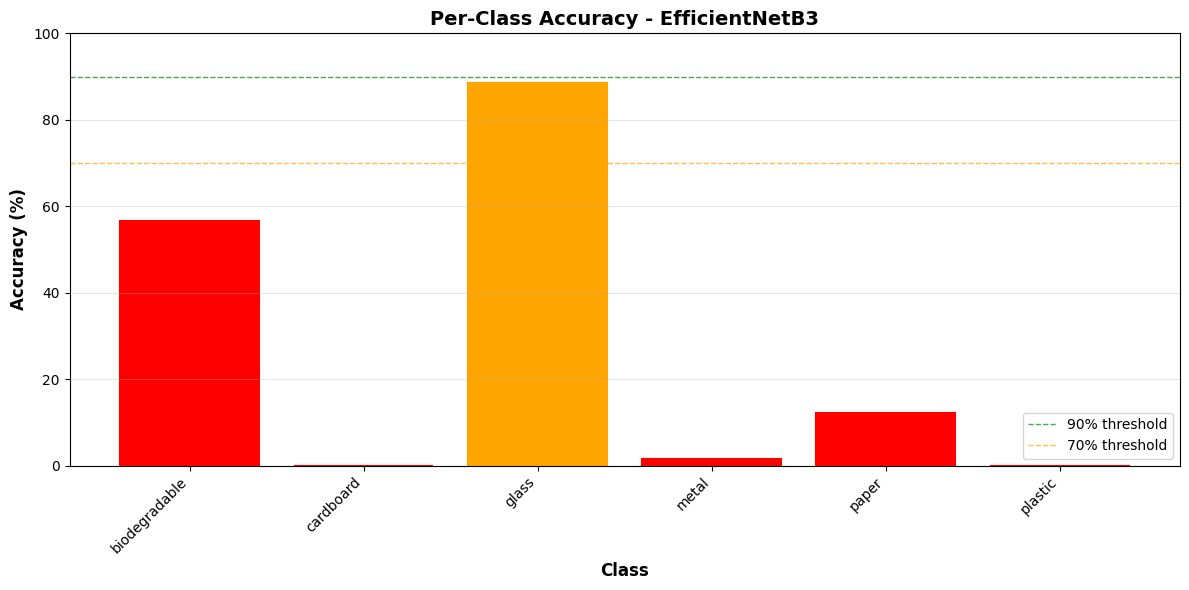


Per-Class Accuracy:
biodegradable       : 56.49%
cardboard           : 0.00%
glass               : 88.44%
metal               : 1.44%
paper               : 12.07%
plastic             : 0.00%


In [ ]:
# Calculate per-class accuracy from confusion matrix
class_accuracy = cm.diagonal() / cm.sum(axis=1)

# Visualize per-class performance
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(class_names, class_accuracy * 100, color='skyblue', edgecolor='navy', linewidth=1.5)

# Color bars based on performance
for i, bar in enumerate(bars):
    if class_accuracy[i] >= 0.9:
        bar.set_color('green')
    elif class_accuracy[i] >= 0.7:
        bar.set_color('orange')
    else:
        bar.set_color('red')

ax.set_xlabel('Class', fontsize=12, fontweight='bold')
ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax.set_title('Per-Class Accuracy - EfficientNetB3', fontsize=14, fontweight='bold')
ax.set_ylim([0, 100])
ax.axhline(y=90, color='green', linestyle='--', linewidth=1, alpha=0.7, label='90% threshold')
ax.axhline(y=70, color='orange', linestyle='--', linewidth=1, alpha=0.7, label='70% threshold')
ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Print per-class statistics
print("\nPer-Class Accuracy:")
for i, class_name in enumerate(class_names):
    print(f"{class_name:20s}: {class_accuracy[i]*100:.2f}%")


## Step 13: Test Model Predictions with Sample Images


1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step


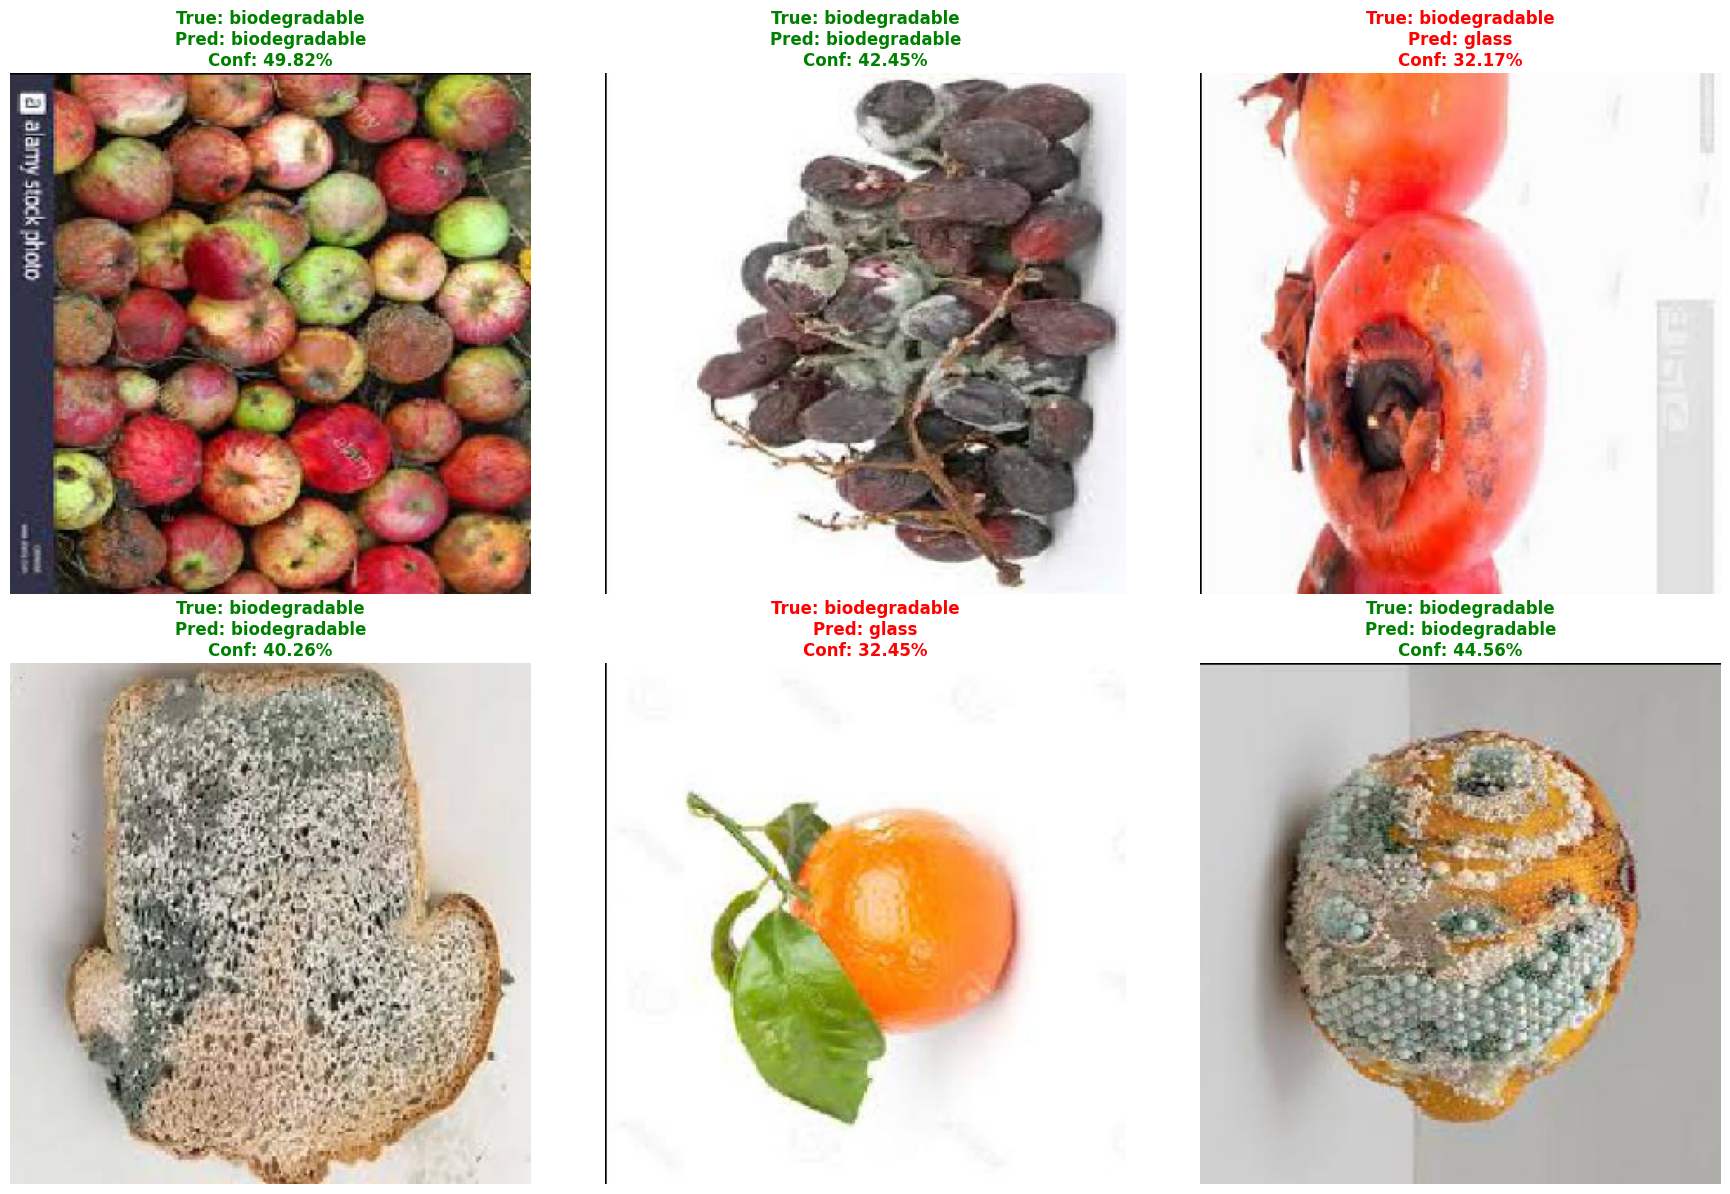

In [ ]:
# Get sample predictions
test_generator.reset()
sample_batch, sample_labels = next(test_generator)
predictions = model.predict(sample_batch)

# Display predictions with confidence scores
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for idx in range(6):
    axes[idx].imshow(sample_batch[idx])

    true_class_idx = np.argmax(sample_labels[idx])
    pred_class_idx = np.argmax(predictions[idx])
    confidence = predictions[idx][pred_class_idx]

    true_label = class_names[true_class_idx]
    pred_label = class_names[pred_class_idx]

    color = 'green' if true_class_idx == pred_class_idx else 'red'
    axes[idx].set_title(
        f'True: {true_label}\nPred: {pred_label}\nConf: {confidence:.2%}',
        color=color,
        fontweight='bold'
    )
    axes[idx].axis('off')

plt.tight_layout()
plt.show()


## Step 14: Save Model


In [ ]:
# Save final model
model.save('efficientnet_garbage_final.h5')
print("Model saved as 'efficientnet_garbage_final.h5'")

# Save model architecture as JSON
model_json = model.to_json()
with open('efficientnet_model_architecture.json', 'w') as json_file:
    json_file.write(model_json)
print("Model architecture saved as 'efficientnet_model_architecture.json'")


Model saved as 'efficientnet_garbage_final.h5'
Model architecture saved as 'efficientnet_model_architecture.json'


## Model Summary

**Architecture:** EfficientNetB3 with custom classification head  
**Transfer Learning:** Pre-trained on ImageNet  
**Training Strategy:** Two-phase (frozen base → fine-tuning)  
**Input Size:** 300x300x3 (optimal for EfficientNetB3)  
**Parameters:** ~12M total (10.7M from EfficientNetB3 base)  
**Optimizer:** Adam with learning rate scheduling  
**Data Augmentation:** Rotation, shift, shear, zoom, flip  

**Key Advantages:**
- Compound scaling for optimal efficiency
- Excellent accuracy-to-parameters ratio
- Smaller model size than ResNet50
- State-of-the-art ImageNet performance
- Suitable for mobile and embedded deployment


In [ ]:
# Optional: Save to Google Drive if running in Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')

    # Define the directory in your Drive to save the models
    save_dir = '/content/drive/MyDrive/GarbageClassificationModels'
    os.makedirs(save_dir, exist_ok=True)

    # Copy models to Drive
    import shutil
    shutil.copy('efficientnet_garbage_best.h5', save_dir)
    shutil.copy('efficientnet_garbage_final.h5', save_dir)
    print(f"Models backed up to Google Drive: {save_dir}")
except ImportError:
    print("Not running in Colab - models saved locally only")


Mounted at /content/drive
Models backed up to Google Drive: /content/drive/MyDrive/GarbageClassificationModels
